# Phase 3: Weather and Hat Sales — Regression Analysis

**Course:** INFO 2950 | **Business:** angelawilliam.com | **Period:** 2014-2026


## 1. Introduction

We examine weather and hat sales at angelawilliam.com, a family-owned business
based in Farmingdale, NY that ships nationwide. Its retailer and wholesaler
customers may purchase ahead of the selling season, so current weather may not
align with their buying decisions.

**Research question:** How are national monthly temperature and precipitation
associated with identified-material hat quantity and the cotton–wool sales mix?

**Summary of findings:** For January 2014–July 2026, neither weather variable is
statistically significant in either model after controlling for calendar month
and year. This is insufficient evidence of an association, not proof of no effect.


## 2. Setup


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from IPython.display import display

plt.rcParams['figure.figsize'] = (10, 4)


**Output 1 — dataset dimensions, date range, and preview.**


In [2]:
# All analysis data comes from the two CSVs produced by data_cleaning.ipynb.
analysis_data = pd.read_csv('csvs/analysis_data.csv', parse_dates=['month'])
# Exclude the incomplete final sales month, as planned in Phase 2.
analysis_data = analysis_data.loc[analysis_data['month'] < '2026-08-01'].copy()

weather_monthly = pd.read_csv('csvs/weather_monthly.csv', parse_dates=['month'])

print('analysis_data shape:', analysis_data.shape)
print('columns:', list(analysis_data.columns))
print('date range:', analysis_data['month'].min().strftime('%Y-%m'),
      'to', analysis_data['month'].max().strftime('%Y-%m'))
print()
print('weather_monthly shape:', weather_monthly.shape)
display(analysis_data.head())


analysis_data shape: (563, 5)
columns: ['month', 'material', 'recorded_quantity', 'temperature_c', 'precipitation_mm']
date range: 2014-01 to 2026-07

weather_monthly shape: (232, 3)


,month,material,recorded_quantity,temperature_c,precipitation_mm
0,2014-01-01,wool,36,-0.800000,34.798
1,2014-03-01,cotton,762,4.727778,60.198
2,2014-03-01,straw,48,4.727778,60.198
3,2014-04-01,cotton,1272,10.938889,72.898
4,2014-04-01,straw,48,10.938889,72.898


## 3. Data Description

### 3.1 About the dataset

**What does our dataset contain?**

`analysis_data.csv` has rows covering months of identified-material sales records from
January 2014 through August 2026. We exclude incomplete August 2026 after loading
the file, so the analysis ends in July 2026. Each row is the total recorded sales quantity for
one hat material in one month. Only rows with an identified material (acrylic, cotton,
felt, leather, polyester, straw, wool) are included; rows with unknown or ambiguous
material are excluded.

| Column | Meaning |
| --- | --- |
| `month` | First day of the month. |
| `material` | Hat material (one of seven identified categories). |
| `recorded_quantity` | Total recorded positive sales quantity for that material that month. |
| `temperature_c` | CONUS average monthly temperature (degrees C). |
| `precipitation_mm` | CONUS area-average monthly precipitation (mm). |

`weather_monthly.csv` covers the full sales period (May 2007 to August 2026).

The cleaning notebook that produced these files:
[data_cleaning.ipynb](https://github.com/bobbybotbop/INFO2950/blob/main/data_cleaning.ipynb)

**Why was this dataset created?**

The sales data were originally collected for accounting purposes by the business.
NOAA maintains the weather data as a public record of historical climate. We combined
them to investigate whether weather conditions relate to hat sales patterns.

**How was the dataset created?**

Raw sales exports were filtered to invoice rows with positive quantities, matched to
a product catalog to identify hats, and classified by material using HTML fields from
the web-store catalog. Sales were aggregated by
month and material. NOAA monthly climate data were reshaped,
converted to metric units, and merged on month. The full pipeline is in
`data_cleaning.ipynb`.

**What factors might affect what was recorded?**

Sales represent purchases actually processed by the business, not total customer
demand. Out-of-stock items would not appear. The accounting exports may be
incomplete (both hit the 32,768-row export limit). Across the full historical dataset, only 11.9% of recorded
quantity has an identified material — the remaining 88.1% is classified unknown
or mixed/ambiguous due to a historical documentation gap in the pre-online-store era.

**What preprocessing was done?**

Invoice rows were filtered; dates and quantities were parsed; products were identified
as hats; materials were classified via catalog HTML fields with keyword fallback;
quantities were aggregated by month and material; unknown/ambiguous material rows
were excluded; the data were restricted to 2014 onward.

**Were people aware their data was being collected?**

The sales records are from normal business operations; we received them from the owner
with permission. The data contain no individual customer information. NOAA weather
data are public domain.

**Where can the original data be found?**

NOAA climate division data: https://www.ncei.noaa.gov/monitoring-content/data/us/climdiv/monthly/current/
Business data: private; project CSVs are in the GitHub `csvs/` folder.

**Why national weather?** The business ships nationwide, so Farmingdale weather
alone would not describe its customer markets. We use NOAA's contiguous-U.S.
(CONUS) averages as a broad proxy because the analysis files lack customer
locations. These averages exclude Alaska and Hawaii and may hide regional
conditions or misrepresent the customer mix (NOAA, n.d.).

### 3.2 Exploratory data analysis

The plots below are generated from `analysis_data.csv` (identified-material sales, 2014+).


#### Figure 1 — monthly identified-material sales

We plot the sum of recorded quantity across identified materials for each observed month to examine variation over time before fitting Model 1.


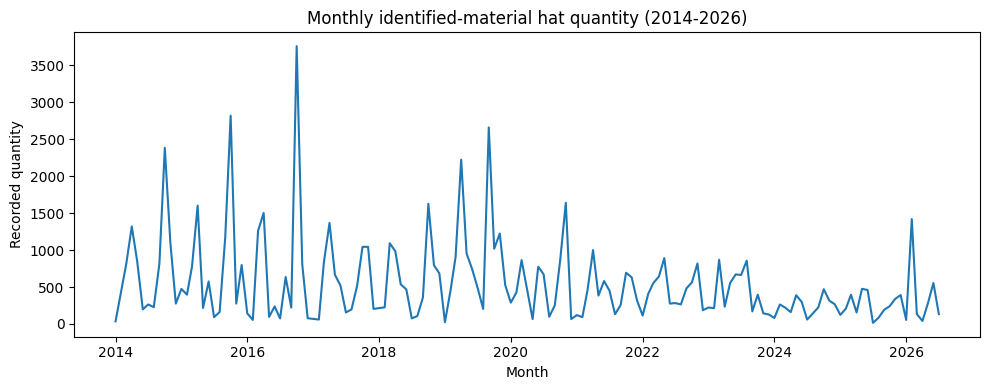

In [3]:
monthly_totals = analysis_data.groupby('month')['recorded_quantity'].sum().reset_index()

plt.figure(figsize=(10, 4))
plt.plot(monthly_totals['month'], monthly_totals['recorded_quantity'])
plt.title('Monthly identified-material hat quantity (2014-2026)')
plt.xlabel('Month')
plt.ylabel('Recorded quantity')
plt.tight_layout()
plt.show()


**Figure 1 interpretation — variation over time.** Monthly identified-material
quantity varies substantially: the analysis file ranges from 15 in July 2025 to
3,759 in October 2016. This motivates considering time and seasonal controls in
Model 1, but the plot alone cannot attribute variation to weather. The line joins
observed months; it does not establish continuous or complete sales coverage.
The 2014 cutoff reflects a material-coverage threshold, not proof that all later
records are complete or representative.


#### Figure 2 — quantity by identified material

We compare cumulative recorded quantities to identify the largest material categories and explain the cotton–wool focus of Model 2.


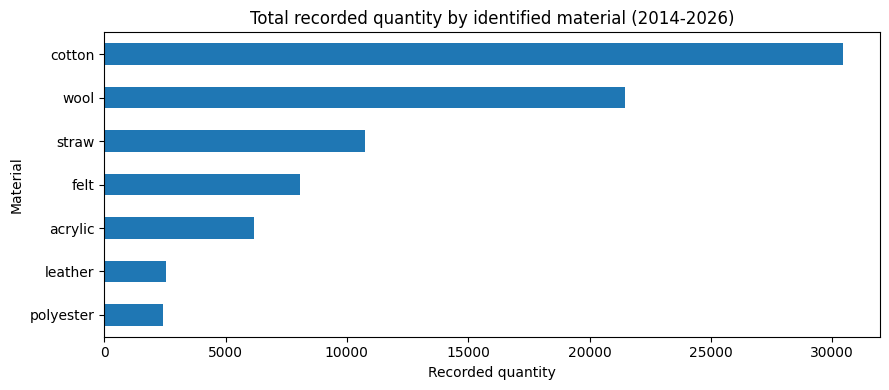

In [4]:
material_totals = (analysis_data.groupby('material')['recorded_quantity']
                   .sum().sort_values())

material_totals.plot(kind='barh', figsize=(9, 4))
plt.title('Total recorded quantity by identified material (2014-2026)')
plt.xlabel('Recorded quantity')
plt.ylabel('Material')
plt.tight_layout()
plt.show()


**Figure 2 interpretation — quantity by material.** Cotton (30,445 recorded units)
and wool (21,456) are the largest identified-material categories in the 2014–2026
analysis file. This supports focusing Model 2 on their relative shares. The bars
show cumulative recorded quantity, not revenue or the number of customers. They
exclude unknown and ambiguous materials, so they do not establish the material
composition of all business sales.


## 4. Preregistration Statements

The following statements restate our Phase 2 plan. The supporting context below
was added during Phase 3; the change in Model 1's sample is disclosed in Section 5.

---

**Preregistration Statement 1: Weather and total monthly sales**

*Hypothesis:* We expect lower temperatures to be associated with higher monthly hat
sales, even after accounting for seasonality and changes over time. We also expect
precipitation to have a relationship with sales, although we do not have a strong
prediction about its direction.

*Supporting context:* Starr-McCluer (2000) finds that unusual weather can affect
monthly retail sales, sometimes with offsetting effects later. We hypothesize
that demand for warmth could increase hat purchases in colder conditions; this
direction is our expectation, not a finding established for this business.

*Proposed analysis:* We will calculate total recorded hat quantity per month and use
multiple linear regression to examine its relationship with temperature and precipitation.
The dependent variable will be the log of monthly sales quantity; the independent variables
will be temperature, precipitation, calendar month (as dummies), and year. We predict
a negative temperature coefficient (beta_temperature < 0) and a nonzero precipitation
coefficient (beta_precipitation != 0).

---

**Preregistration Statement 2: Weather and cotton-wool sales mix**

*Hypothesis:* Cotton hats make up a larger share of sales relative to wool hats during
warmer months, even after accounting for precipitation, seasonal patterns, and year.

*Supporting context:* Wool's crimp traps air and provides insulation (The Woolmark
Company, n.d.). This motivates our expectation that wool could be relatively more
popular in cold conditions, increasing cotton's relative share in warmer conditions.
This is a sales hypothesis, not a direct consequence of fibre properties; hat
construction and customer preferences also matter.

*Proposed analysis:* For each month, we calculate the proportion of cotton quantity out of
combined cotton and wool quantity. Months where neither material has recorded sales are
excluded (the proportion would be undefined). We then regress this proportion on temperature,
precipitation, calendar month (as dummies), and year. We predict a positive temperature
coefficient (beta_temperature > 0).


## 5. Data Analysis

We use January 2014–July 2026 records and exclude incomplete August 2026, as planned
in Phase 2. The 2014 start is a practical coverage threshold: it is the first year
identified materials reach 10% of annual recorded quantity. It does not establish
that the retained sample represents all sales.

**Change from preregistration:** Phase 2 proposed total monthly hat quantity for
Model 1. Our current cleaning export contains only identified-material records,
so Model 1 instead analyzes that subset. Material labels are not required to count
total sales; this restriction limits our conclusions to identified products.
Model 2 uses the cotton and wool subset, as planned.

Both OLS models include calendar-month indicators (January is the reference) and
a linear year trend. Four months within the period have no identified-material
records, leaving 147 observed months; 140 have cotton or wool records.


### 5.1 Model 1: Log monthly hat quantity vs. weather

**Dependent variable:** log(total monthly identified-material hat quantity)
**Predictors:** temperature (C), precipitation (mm), calendar-month dummies, year

We log-transform quantity to handle the right-skewed distribution of monthly sales totals,
as preregistered. The unit of observation is one row per month (quantity summed across
all identified materials).


**Output 2 — Model 1 sample and descriptive statistics.**


In [5]:
# Aggregate to one row per month (sum across all identified materials).
monthly_totals = analysis_data.groupby('month')['recorded_quantity'].sum().reset_index()
weather_by_month = (analysis_data[['month', 'temperature_c', 'precipitation_mm']]
                    .drop_duplicates('month'))
model1_data = monthly_totals.merge(weather_by_month, on='month', validate='one_to_one')
model1_data['log_quantity'] = np.log(model1_data['recorded_quantity'])
model1_data['month_num'] = model1_data['month'].dt.month
model1_data['year_num'] = model1_data['month'].dt.year

print('Model 1 observations:', len(model1_data))
print('Date range:', model1_data['month'].min().strftime('%Y-%m'),
      'to', model1_data['month'].max().strftime('%Y-%m'))
display(model1_data[['log_quantity', 'temperature_c', 'precipitation_mm']].describe().round(3))


Model 1 observations: 147
Date range: 2014-01 to 2026-07


,log_quantity,temperature_c,precipitation_mm
count,147.000,147.000,147.000
mean,5.865,12.571,66.463
std,1.020,8.291,15.611
min,2.708,-1.578,24.384
25%,5.273,4.733,56.134
50%,5.981,12.378,66.040
75%,6.671,20.469,76.327
max,8.232,24.950,113.538


**Output 3 — Model 1 regression results.**


In [6]:
model1 = smf.ols(
    'log_quantity ~ temperature_c + precipitation_mm + C(month_num) + year_num',
    data=model1_data
).fit()

print(model1.summary())


                            OLS Regression Results                            
Dep. Variable:           log_quantity   R-squared:                       0.411
Model:                            OLS   Adj. R-squared:                  0.348
Method:                 Least Squares   F-statistic:                     6.572
Date:                Tue, 10 Nov 2026   Prob (F-statistic):           5.93e-10
Time:                        12:26:59   Log-Likelihood:                -172.13
No. Observations:                 147   AIC:                             374.3
Df Residuals:                     132   BIC:                             419.1
Df Model:                          14                                         
Covariance Type:            nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
Intercept            128.4540     39

#### Interpretation of Model 1

**Results (Output 3):** Across 147 months, R² = 0.411, so the full model explains
41.1% of variation in log quantity, including the time controls. Holding other
predictors fixed, a 1°C temperature increase corresponds to approximately 1.0%
higher quantity (coefficient = 0.0099, p = 0.8763); 1 mm more precipitation
corresponds to approximately 0.6% higher quantity (coefficient = 0.0060,
p = 0.2909). Neither association is significant, and temperature's estimated
sign is opposite to our prediction.

**Predicting:** The model predicts log quantity. Its R² describes in-sample fit,
not forecast accuracy; predictions outside the observed conditions require caution.

**Residuals and outliers (Figure 3):** Residuals lie on both sides of zero without
an obvious curved pattern or steadily widening spread. A few errors reach roughly
-2.3 to +2.2 log units, showing that some months are poorly predicted. These months
warrant checking for unusual orders or missing records. This plot alone does not
establish that errors are independent over time.


#### Figure 3 — Model 1 residuals versus fitted values

Each point is a month; both axes use log-quantity units. Distance from zero shows
prediction error.


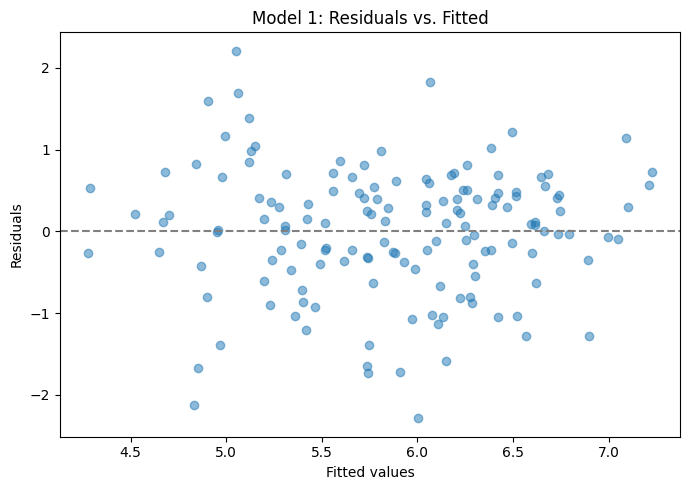

In [7]:
fig, ax = plt.subplots(figsize=(7, 5))

fitted1 = model1.fittedvalues
resid1 = model1.resid

ax.scatter(fitted1, resid1, alpha=0.5)
ax.axhline(0, linestyle='--', color='gray')
ax.set_xlabel('Fitted values')
ax.set_ylabel('Residuals')
ax.set_title('Model 1: Residuals vs. Fitted')


plt.tight_layout()
plt.show()


### 5.2 Model 2: Cotton proportion of cotton+wool sales vs. weather

**Dependent variable:** cotton quantity / (cotton + wool quantity) per month
**Predictors:** temperature (C), precipitation (mm), calendar-month dummies, year
**Restriction:** months where neither cotton nor wool has recorded sales are excluded,
since the proportion is undefined in those months (no information about the cotton-wool mix).


**Output 4 — Model 2 sample and descriptive statistics.**


In [8]:
cotton = (analysis_data[analysis_data['material'] == 'cotton']
          [['month', 'recorded_quantity']]
          .rename(columns={'recorded_quantity': 'cotton_qty'}))
wool = (analysis_data[analysis_data['material'] == 'wool']
        [['month', 'recorded_quantity']]
        .rename(columns={'recorded_quantity': 'wool_qty'}))

model2_data = (cotton.merge(wool, on='month', how='outer')
               .fillna({'cotton_qty': 0, 'wool_qty': 0}))
model2_data = model2_data.merge(weather_by_month, on='month', how='inner')
model2_data['total_cw'] = model2_data['cotton_qty'] + model2_data['wool_qty']

dropped = (model2_data['total_cw'] == 0).sum()
model2_data = model2_data[model2_data['total_cw'] > 0].copy()
print(f'{len(model2_data)} of {len(model1_data)} observed months have cotton or wool records.')

model2_data['cotton_proportion'] = model2_data['cotton_qty'] / model2_data['total_cw']
model2_data['month_num'] = model2_data['month'].dt.month
model2_data['year_num'] = model2_data['month'].dt.year

print('Model 2 observations:', len(model2_data))
display(model2_data[['cotton_proportion', 'temperature_c', 'precipitation_mm']].describe().round(3))


140 of 147 observed months have cotton or wool records.
Model 2 observations: 140


,cotton_proportion,temperature_c,precipitation_mm
count,140.000,140.000,140.000
mean,0.611,12.769,66.296
std,0.406,8.137,15.365
min,0.000,-1.578,24.384
25%,0.201,4.953,56.515
50%,0.833,12.514,66.421
75%,1.000,20.631,76.264
max,1.000,24.950,113.538


**Output 5 — Model 2 regression results.**


In [9]:
model2 = smf.ols(
    'cotton_proportion ~ temperature_c + precipitation_mm + C(month_num) + year_num',
    data=model2_data
).fit()

print(model2.summary())


                            OLS Regression Results                            
Dep. Variable:      cotton_proportion   R-squared:                       0.743
Model:                            OLS   Adj. R-squared:                  0.714
Method:                 Least Squares   F-statistic:                     25.78
Date:                Tue, 10 Nov 2026   Prob (F-statistic):           2.79e-30
Time:                        12:26:59   Log-Likelihood:                 23.230
No. Observations:                 140   AIC:                            -16.46
Df Residuals:                     125   BIC:                             27.66
Df Model:                          14                                         
Covariance Type:            nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
Intercept             39.9683     10

#### Interpretation of Model 2

**Results (Output 5):** Across 140 months, R² = 0.743, so the full model explains
74.3% of variation in cotton share, including the time controls. Holding other
predictors fixed, a 1°C temperature increase corresponds to a 0.86-percentage-point
decrease in cotton share (coefficient = -0.0086, p = 0.6236). A 1 mm precipitation
increase corresponds to approximately a 0.11-percentage-point increase
(coefficient = 0.0011, p = 0.4689). Neither association is significant, and the
temperature estimate does not support our predicted positive relationship.

**Residuals and prediction (Figure 4):** Residuals form downward-sloping bands,
consistent with months whose observed cotton shares equal 0 or 1. Their spread
varies across fitted values, and a few errors approach ±0.7. Some fitted shares
fall below 0 or above 1, which are impossible as actual proportions. These patterns
highlight limitations of linear regression for a bounded outcome and raise concerns
about constant error variance, so the conventional OLS p-values require caution.


#### Figure 4 — Model 2 residuals versus fitted values

Each point is a month. The axes show predicted cotton share and observed minus
predicted share.


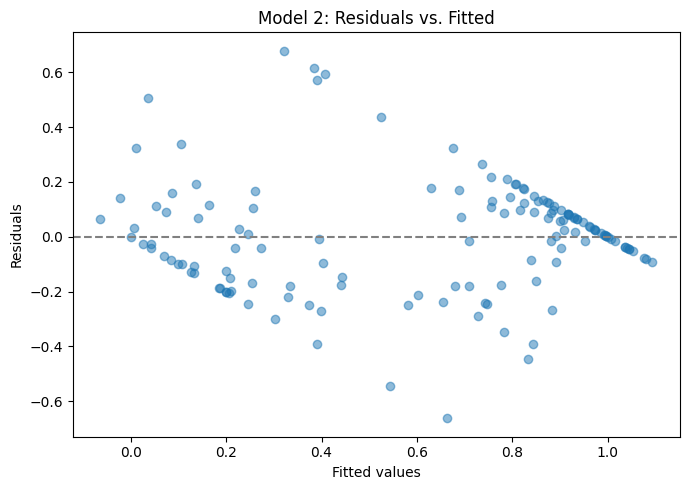

In [10]:
fig, ax = plt.subplots(figsize=(7, 5))

fitted2 = model2.fittedvalues
resid2 = model2.resid

ax.scatter(fitted2, resid2, alpha=0.5)
ax.axhline(0, linestyle='--', color='gray')
ax.set_xlabel('Fitted values')
ax.set_ylabel('Residuals')
ax.set_title('Model 2: Residuals vs. Fitted')


plt.tight_layout()
plt.show()


## 6. Evaluation of Significance

We evaluate both preregistered hypotheses at alpha = 0.05, using the two-sided
coefficient tests reported below.

**Model 1:** Temperature (p = 0.8763) and precipitation (p = 0.2909) are not
statistically significant. We fail to reject each null hypothesis that the
corresponding coefficient is zero. The positive temperature estimate is opposite
to our predicted negative association, and the results do not support our first
preregistration statement.

**Model 2:** Temperature (p = 0.6236) and precipitation (p = 0.4689) are also not
significant. We fail to reject both zero-coefficient null hypotheses. The negative
temperature estimate does not support our second prediction that warmer conditions
are associated with a higher cotton share.

Overall, we find insufficient evidence of a contemporaneous national weather
association after controlling for calendar month and year. This does not prove
that weather has no effect. Geographic averaging, missing sales information, and
wholesale purchasing ahead of the season may obscure a relationship. The residual
patterns in Model 2 also raise concerns about the assumptions behind its conventional
OLS p-values.


**Output 6 — two-sided coefficient tests at alpha = 0.05.**


In [11]:
print('=' * 65)
print('Hypothesis 1 (Model 1 — temperature coefficient)')
print('=' * 65)
t1 = model1.params['temperature_c']
p1t = model1.pvalues['temperature_c']
p1p = model1.pvalues['precipitation_mm']
pr1 = model1.params['precipitation_mm']

print(f'  temperature_c:    coef = {t1:+.4f},  p = {p1t:.4f}')
if p1t < 0.05 and t1 < 0:
    print('  Result: REJECT H0 — negative and significant at alpha=0.05.')
    print('  Supports the preregistered direction (beta_temperature < 0).')
elif p1t < 0.05:
    print('  Result: REJECT H0 — significant at alpha=0.05 but POSITIVE.')
    print('  Contradicts the preregistered direction (beta_temperature < 0).')
else:
    print('  Result: FAIL TO REJECT H0 — not significant at alpha=0.05.')
    print('  Insufficient evidence that temperature predicts log monthly sales.')

print()
print(f'  precipitation_mm: coef = {pr1:+.4f},  p = {p1p:.4f}')
if p1p < 0.05:
    print('  Result: REJECT H0 — significant at alpha=0.05.')
    print('  Supports the preregistered hypothesis (beta_precipitation != 0).')
else:
    print('  Result: FAIL TO REJECT H0 — not significant at alpha=0.05.')
    print('  Insufficient evidence that precipitation predicts log monthly sales.')

print()
print('=' * 65)
print('Hypothesis 2 (Model 2 — temperature coefficient)')
print('=' * 65)
t2 = model2.params['temperature_c']
p2t = model2.pvalues['temperature_c']
p2p = model2.pvalues['precipitation_mm']
pr2 = model2.params['precipitation_mm']

print(f'  temperature_c:    coef = {t2:+.4f},  p = {p2t:.4f}')
if p2t < 0.05 and t2 > 0:
    print('  Result: REJECT H0 — positive and significant at alpha=0.05.')
    print('  Supports the preregistered direction (beta_temperature > 0).')
elif p2t < 0.05:
    print('  Result: REJECT H0 — significant at alpha=0.05 but NEGATIVE.')
    print('  Contradicts the preregistered direction (beta_temperature > 0).')
else:
    print('  Result: FAIL TO REJECT H0 — not significant at alpha=0.05.')
    print('  Insufficient evidence that temperature predicts the cotton proportion.')

print()
print(f'  precipitation_mm: coef = {pr2:+.4f},  p = {p2p:.4f}')
if p2p < 0.05:
    print('  Result: precipitation is significant at alpha=0.05 in Model 2.')
else:
    print('  Result: precipitation is not significant at alpha=0.05 in Model 2.')


Hypothesis 1 (Model 1 — temperature coefficient)
  temperature_c:    coef = +0.0099,  p = 0.8763
  Result: FAIL TO REJECT H0 — not significant at alpha=0.05.
  Insufficient evidence that temperature predicts log monthly sales.

  precipitation_mm: coef = +0.0060,  p = 0.2909
  Result: FAIL TO REJECT H0 — not significant at alpha=0.05.
  Insufficient evidence that precipitation predicts log monthly sales.

Hypothesis 2 (Model 2 — temperature coefficient)
  temperature_c:    coef = -0.0086,  p = 0.6236
  Result: FAIL TO REJECT H0 — not significant at alpha=0.05.
  Insufficient evidence that temperature predicts the cotton proportion.

  precipitation_mm: coef = +0.0011,  p = 0.4689
  Result: precipitation is not significant at alpha=0.05 in Model 2.


## 7. Conclusions

Using January 2014–July 2026 data, we examined whether national monthly temperature
and precipitation are associated with identified-material hat sales and the
cotton–wool sales mix, after controlling for calendar month and year.

**Monthly sales quantity:** Model 1 provides insufficient evidence that either
weather variable is associated with monthly identified-material quantity. The
temperature estimate is positive, opposite to our prediction that colder conditions
would be associated with higher sales, but it is not statistically significant.

**Cotton–wool sales mix:** Model 2 also finds no statistically significant weather
association. Its negative temperature estimate does not support our prediction that
cotton's share would increase in warmer conditions. Although the full model explains
74.3% of variation in cotton share, that includes the calendar-month and year
controls and does not establish that weather explains the sales mix.

Overall, neither preregistered weather hypothesis is supported by these models.
This does not prove that weather has no effect: national averages may obscure local
conditions, and wholesale customers may buy before the weather relevant to their
orders occurs. Incomplete records and missing material labels also limit the
analysis. In particular, Model 1 represents identified products rather than all
business sales, and Model 2's residual patterns warrant caution about its inference.


## 8. Limitations

1. **B2B buying-ahead:** Many customers are retailers or wholesalers purchasing in
   advance of expected weather. Our models use contemporaneous weather; the
   relationship may involve a delay. Future analysis could test
   lagged weather variables.

2. **Incomplete sales records:** Both accounting exports hit the 32,768-row limit,
   suggesting some transactions may be missing. Five months in the full period have
   no recorded sales at all. Systematic gaps could bias monthly totals in certain periods.

3. **Missing material information:** Across the full historical dataset, 88.1% of recorded quantity has unknown or
   ambiguous material. The cotton and wool products we can identify are not guaranteed
   to represent the full sales mix, and patterns in identified materials may not
   generalize to the whole business.

4. **National weather:** CONUS averages may hide regional conditions. Without
   customer locations, we cannot assess how well they represent customer weather.

5. **Statistical limitations:** Monthly errors may be correlated over time, and
   Model 2 shows uneven residual spread and predictions outside 0–1. The models
   use conventional OLS standard errors; robust inference would be a useful
   sensitivity check. Seasonal temperature patterns may also make weather effects
   difficult to separate from calendar-month controls.


## 9. Acknowledgements and Bibliography

Sales and inventory data were provided by the owner of angelawilliam.com. We used
NOAA weather data and Python packages pandas, NumPy, Matplotlib, and statsmodels.

1. National Oceanic and Atmospheric Administration. (n.d.). *Monthly U.S. climate
   divisional data*. https://www.ncei.noaa.gov/monitoring-content/data/us/climdiv/monthly/current/
2. Starr-McCluer, M. (2000). *The effects of weather on retail sales*. Finance and
   Economics Discussion Series 2000-08, Federal Reserve Board.
   https://www.federalreserve.gov/pubs/feds/2000/200008/200008pap.pdf
3. The Woolmark Company. (n.d.). *Wool is naturally breathable*.
   https://www.woolmark.com/industry/research/factsheets/wool-is-naturally-breathable/
